# TRABAJO PRACTICO INTEGRADOR - SEGUNDO PARCIAL
#### INTEGRANTES:
- Bianciotto Sofia - 1241171
- Cebreiros Juana - 1238673
- Lacava Giuliana - 1239334
- Lazaro Martina - 1238503
##### TEMA: Utilizaremos un dataset de una veterinaria, con el objetivo de predecir un diagnostico segun las variables dadas.

### PARTE 1 - CARGA DE DATOS

HACER:
- ver de transformar booking date e intake date a date (esta como string)
- ver de transformar patient ID a str (esta como int)
- averiguar si las fachas que faltan en booking date son por falta de registro, o porque llegaron de emergencia. 
- ver si se puede agregar algun registro duplicado, para trabajar con la visualizacion y eliminacion (dsp se borra el duplicado, asique no afectaria el analisis original)
- ver que columnas elimino por nulos, y ver cuales puedo imputar por la media o mediana (o moda)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [17]:
df = pd.read_csv("Vet_Clinical_Dataset.csv")
print("el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:")
df.shape

el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:


(2000, 15)

### PARTE 2 - EDA

En los siguientes cuadros de codigo, revisaremos el dataset y los datos del mismo, verificando si hay valores nulos, duplicados, faltantes. Luego analizaremos que hacer frente a cada problema encontrado. 

In [6]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake location', 'Body condition score', 'wood lamp fungal',
       'definitive diagnosis'],
      dtype='str')

Que informacion nos da cada columna:
- Patitient ID: codigo de identificacion unico para cada caso. 
- ownership_status: origen del animal (owned - recued - lost_rescued)
- intake date: fecha en que el animal fue llevado a la consulta para la evaluacion clinica
- booking date: fecha de una consulta con reserva previa
- intake location: area geografica (en la ciudad de Makati)
- species: tipo de animal
- breed: clasificacion de raza
- age: edad del paciente
- sex: genero del paciente
- weight: peso del paciente (en kg)
- temperature: temperatura corporal al ingreso a la consulta (en grados Celsius)
- heart rate: latidos por minuto
- body condition score: condicion corporal en una escala del 1 (escualido) al 9 (obesidad)
- wood lamp fungal: test para detectar infecciones (positive - negative)
- definitive diagnosis: el diagnostico final dictado por el veterinario de turno

In [ ]:
df.head(3) #primero 3 registros del dataset


,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis


In [ ]:
df.tail(3) #ultimos 3 registros del dataset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1999,24034062,rescued,3/15/2024,NaN,feline,Siamese,12 weeks,female,2.0,38.3,NaN,"Bel-Air, Makati City",7.0,Negative,Ear Mites and Yeast Otitis


In [ ]:
df.sample(5) #5 registros aleatorios del datset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
265,24127455,rescued,12/11/2024,NaN,canine,Aspin,10 years,male,11.6,38.8,82.0,Makati Central Business District,5.0,Negative,Bacterial Dermatitis and Bacterial Otitis
259,23030961,rescued,2023-03-09,NaN,canine,Golden Retriever,12 years,male,3.8,38.4,83.0,"San Lorenzo, Makati City",4.0,Negative,Yeast Otitis
1912,24091216,lost_rescued,9/18/2024,NaN,canine,Aspin,11 months,female,15.0,38.8,113.0,"Urdaneta, Makati City",7.0,Positive,Ringworm and Yeast Otitis
788,24024659,rescued,2/25/2024,NaN,canine,Aspin,4 months,female,2.5,38.6,134.0,"Comembo, Makati City",5.0,Negative,Bacterial Dermatitis
1483,24105753,rescued,10/26/2024,NaN,feline,Puspin,8 months,female,3.3,38.7,220.0,"South Cembo, Makati City",4.0,Positive,Ringworm and Yeast Otitis


In [ ]:
df.info() #panorama general del dataset. cantidad de filas, columnas, nombres de las columnas, cantidad de valores no nulos por columna y tipo de dato de cada columna.

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient ID            2000 non-null   int64  
 1   ownership_status      2000 non-null   str    
 2   intake date           866 non-null    str    
 3   booking date          1134 non-null   str    
 4   species               2000 non-null   str    
 5   breed                 2000 non-null   str    
 6   age                   2000 non-null   str    
 7   sex                   2000 non-null   str    
 8   weight                2000 non-null   float64
 9   temperature           2000 non-null   float64
 10  heart rate            1689 non-null   float64
 11  intake location       866 non-null    str    
 12  Body condition score  1942 non-null   float64
 13  wood lamp fungal      2000 non-null   str    
 14  definitive diagnosis  2000 non-null   str    
dtypes: float64(4), int64(1), str(10)

(2000, 15)

podemos observar que el datset contiene 2000 filas y 15 columnas, de las cuales 10 no tienen ningun valor nulo. "intake date" - "booking date" - "heart rate" - "intake location" - "body condition score" tienen valores nulos. 

In [ ]:
df.describe() #resmen estadistico de las variables numericas

,Patient ID,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,35.800000,39.300000,230.000000,7.000000


- count: cantidad de valores no nulos
- mean: promedio
- std: desvio estandar
- min: valor minimo 
- 25% - 75%: primer y tercer cuartil
- 50%: mediana
- max: valor maximo

observaciones:
- "heart rate" y "body condition score" tiene valores nulos 
- este no es un analisis significativo para la variable Patient ID, ya que es una variable unica de cada paciente. Serviria mas analizarla como "object". (ver de hacer una transformacion a object)
- en "weight" y "heart rate" el promedio se encuentra alejado del valor de la media, tienen un desvio estandar elevado, por lo que los datos estan dispersos. Puede significar la presencia de algun outlier.

In [ ]:
df.describe(include="object") #ahora aplicado a las variables categoricas 

C:\Users\juana\AppData\Local\Temp\ipykernel_7424\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,ownership_status,intake date,booking date,species,breed,age,sex,intake location,wood lamp fungal,definitive diagnosis
count,2000,866,1134,2000,2000,2000,2000,866,2000,2000
unique,3,586,678,2,13,26,2,16,2,13
top,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,"South Cembo, Makati City",Negative,Ear Mites and Yeast Otitis
freq,1134,4,6,1199,484,131,1008,69,1683,181


- count: valores no nulos
- unique: cantidad de valores unicos
- top: valor mas frecuete
- freq: frecuencia del valor mas frecuente

observaciones: 
- sobre "ownership status":     
        - el valor mas repetido es "owned" apareciendo 1134 veces de 2000 registros totales, lo que significa que al menos de la mitad de los animmales atendidos tenian dueño. 
- sobre "intake date":
       - hay varios valores faltantes, de 2000 ingresos, solo se registraron 866 en esta categoria. las fechas de ingreso estan muy distribuidas, no existe una en particular que acumule un gran porcentaje de animales ingresados. 
- sobre "booking date":
        - lo mismo que para la variable anterior, muchos datos faltantes 
- sobre "species":
        - hay solamente 2 tipos de especies, siendo apenas mas de la mitad "canine"
- sobre "breed":
        - hay 13 razas diferentes, siendo "Aspin" la as frecuente, representando el 24,2% de los registros
- sobre "age":
        - de 26 edades registradas, ninguna representa una gran mayoria de los datos. 
- sobre "sex":
        - el sexo femenino esta muy levemente mas repetido que el sexo masculino (los dos unicos valores posibles)
- sobre "intake location":
        - ninguna de las 16 ubicaciones esta mucho mas repetida que el resto. hay que considerar que hay mas de la mitad de valores faltantes
- sobre "wood lamp fungal":
        - la mayoria de los resultados dio negativo (el 84,15%). solo el 15,85% dio positivo. todos los animales se fueron sometidos  este test.
- sobre "definitive diagnosis":
        - hubo 13 diagnosticos distintos, el mas repetido "ear mites and yeast otitis", sin predominar ampliamente por sobre el resto

In [ ]:
df.describe(include="all") #esta es la forma de incluir lo de ambas tablas anteriores en una sola

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
count,2.000000e+03,2000,866,1134,2000,2000,2000,2000,2000.000000,2000.000000,1689.000000,866,1942.000000,2000,2000
unique,NaN,3,586,678,2,13,26,2,NaN,NaN,NaN,16,NaN,2,13
top,NaN,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,NaN,NaN,NaN,"South Cembo, Makati City",NaN,Negative,Ear Mites and Yeast Otitis
freq,NaN,1134,4,6,1199,484,131,1008,NaN,NaN,NaN,69,NaN,1683,181
mean,2.404418e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.652150,38.711250,129.512729,NaN,4.845520,NaN,NaN
std,8.212429e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.340566,0.294859,41.831217,NaN,1.453319,NaN,NaN
min,2.301009e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700000,38.000000,66.000000,NaN,3.000000,NaN,NaN
25%,2.309690e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000,38.500000,96.000000,NaN,3.000000,NaN,NaN
50%,2.406290e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.500000,38.700000,115.000000,NaN,5.000000,NaN,NaN
75%,2.503390e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.700000,39.000000,165.000000,NaN,6.000000,NaN,NaN


In [27]:
df["ownership_status"].value_counts()

ownership_status
owned           1134
rescued          684
lost_rescued     182
Name: count, dtype: int64

de 2000 animales: 56,7% tenian dueño - 32,4% fueron rescatados - 9,1% fueron "lost_rescued"

In [28]:
df["breed"].value_counts() #cuantos ingresos de cada raza

breed
Aspin                 484
Puspin                342
Persian               121
Domestic Shorthair    120
Siberian Husky        113
Chihuahua             110
British Shorthair     109
Siamese               109
French Bulldog        109
Shih Tzu              102
Golden Retriever       98
Pomeranian             93
Poodle                 90
Name: count, dtype: int64

In [29]:
df["intake location"].value_counts() #cuantos ingresos por cada ubicacion

intake location
South Cembo, Makati City            69
Palanan, Makati City                64
Pitogo, Makati City                 64
Urdaneta, Makati City               62
Bel-Air, Makati City                56
Guadalupe Nuevo, Makati City        56
East Rembo, Makati City             55
Pembo, Makati City                  54
San Lorenzo, Makati City            53
Guadalupe Viejo, Makati City        53
Makati Central Business District    51
Rizal, Makati City                  49
West Rembo, Makati City             47
Comembo, Makati City                46
Poblacion, Makati City              46
San Antonio, Makati City            41
Name: count, dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

no hay ningun registro con exactamente los mismos valores en todas sus columnas.

In [ ]:
df.isnull().sum() #nos muestra los valores nulos por columna

Patient ID                 0
ownership_status           0
intake date             1134
booking date             866
species                    0
breed                      0
age                        0
sex                        0
weight                     0
temperature                0
heart rate               311
intake location         1134
Body condition score      58
wood lamp fungal           0
definitive diagnosis       0
dtype: int64

Podemos observar:
- "intake date" tiene 1134 valores nulos.
- "booking date" tiene 866 valores nulos.
- "heart rate" tiene 311 valores nulos.
- "intake location" tiene 1134 valores nulos. 
- "body condition score" tiene 58 valores nulos.
- todo el resto de las columnas no tiene valores nulos. 

In [ ]:
nulos_porcentaje = df.isnull().sum() / (len(df)) * 100

print(nulos_porcentaje) #nos muestra el porcentaje de datos nulos por columna

Patient ID               0.00
ownership_status         0.00
intake date             56.70
booking date            43.30
species                  0.00
breed                    0.00
age                      0.00
sex                      0.00
weight                   0.00
temperature              0.00
heart rate              15.55
intake location         56.70
Body condition score     2.90
wood lamp fungal         0.00
definitive diagnosis     0.00
dtype: float64


In [ ]:
df[df.isnull().any(axis=1)] #visualizacion de registros con al menos 1 dato faltante

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis
3,23014013,owned,NaN,2023-01-07,feline,Puspin,12 years,female,4.1,38.7,NaN,NaN,3.0,Negative,Ear Mites and Yeast Otitis
4,24073658,rescued,7/17/2024,NaN,canine,Aspin,3 years,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,25097643,owned,NaN,2025-09-02,canine,Aspin,9 months,female,13.3,39.0,104.0,NaN,7.0,Negative,Bacterial Dermatitis
1996,23052008,rescued,5/20/2023,NaN,canine,French Bulldog,7 years,female,22.0,38.9,NaN,Makati Central Business District,5.0,Negative,Atopic Dermatitis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis


In [37]:
df1 = df.dropna()

df1.shape

(0, 15)

In [38]:
df1.head()

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis


## Agrupaciones y Visualizaciones:
En esta sección analizaremos los datos agrupados por especie y sexo, estudiaremos los diagnósticos más frecuentes y evaluaremos la viabilidad de una serie temporal.

In [15]:
#agrupacion de datos cruzando las columnas "definitive diagnosis", "species" y "sex"
resumen_cruzado = df.groupby(["definitive diagnosis", "species", "sex"]).agg(
    total_casos=('Patient ID', 'count'),
    peso_promedio=('weight', 'mean'),
    temp_promedio=('temperature', 'mean'),
    bcs_promedio=('Body condition score', 'mean')
).reset_index()

# Mostramos el resultado ordenado por los que tienen más casos
display(resumen_cruzado.sort_values(by='total_casos', ascending=False).head(10))

,definitive diagnosis,species,sex,total_casos,peso_promedio,temp_promedio,bcs_promedio
8,Bacterial Dermatitis,canine,female,66,9.781818,38.769697,5.107692
5,Atopic Dermatitis and Bacterial Otitis,canine,male,59,11.205085,38.783051,4.982759
33,Ringworm and Yeast Otitis,canine,male,59,11.889831,38.686441,4.962264
24,Ear Mites and Yeast Otitis,canine,female,55,10.092727,38.754545,4.962963
29,Ringworm,canine,male,55,7.276364,38.745455,5.327273
25,Ear Mites and Yeast Otitis,canine,male,52,11.592308,38.725000,4.666667
37,Yeast Dermatitis,canine,male,51,11.049020,38.813725,5.180000
41,Yeast Dermatitis and Yeast Otitis,canine,male,51,9.950980,38.749020,4.760000
17,Bacterial Otitis,canine,male,51,10.041176,38.739216,4.666667
20,Ear Mites,canine,female,50,11.378000,38.814000,5.306122


### Gráfico de distribución de diagnósticos
A continuación, visualizamos la frecuencia de los diagnósticos definitivos comparados entre especies para detectar patrones relevantes:

<Figure size 1100x600 with 0 Axes>

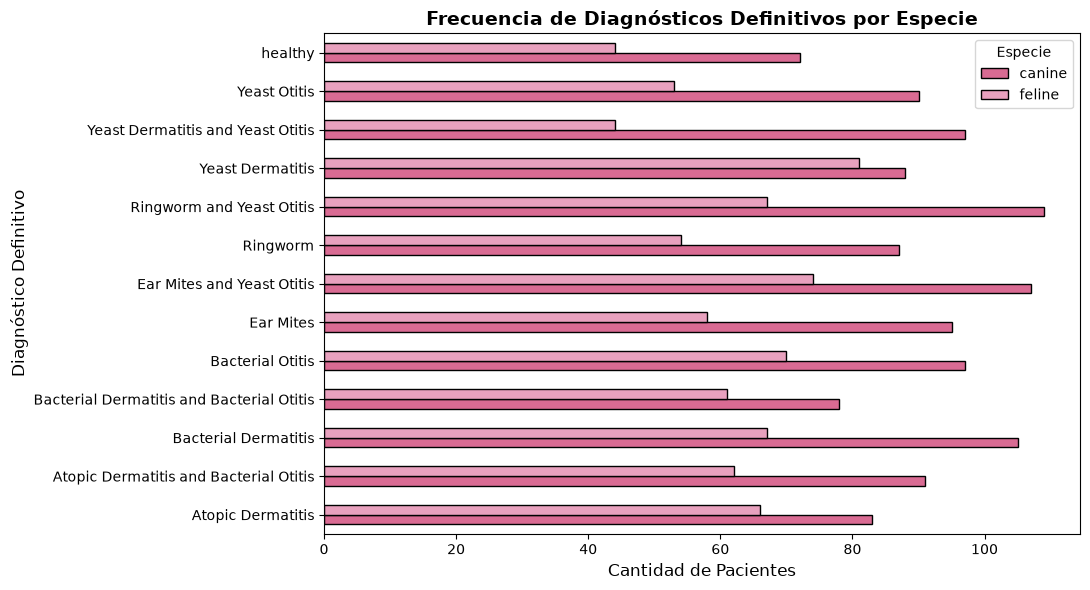

In [16]:
import matplotlib.pyplot as plt
#Tabla cruzada de diagnósticos definitivos según la especie
diag_especie = pd.crosstab(df['definitive diagnosis'], df['species'])

#grafico de barras apiladas para visualizar la distribución de diagnósticos por especie
plt.figure(figsize=(11, 6))
diag_especie.plot(kind='barh', figsize=(11, 6), color=['#d96b93', '#e8a1be'], edgecolor='black')
plt.title('Frecuencia de Diagnósticos Definitivos por Especie', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Pacientes', fontsize=12)
plt.ylabel('Diagnóstico Definitivo', fontsize=12)
plt.legend(title='Especie')
plt.tight_layout()
plt.show()

### Interpretación de Hallazgos y Análisis Temporal

* **Diagnósticos más frecuentes:** Los motivos de consulta más repetidos en la veterinaria son *Ear Mites and Yeast Otitis* (181 casos), *Ringworm and Yeast Otitis* (176 casos) y *Bacterial Dermatitis* (172 casos).
* **Diferencias entre grupos:** Los caninos concentran mayor volumen de casos totales (destacando en infecciones fúngicas y de ácaros), mientras que los felinos muestran una alta incidencia en *Yeast Dermatitis*.

#### Justificación sobre la Serie Temporal:
* **¿Es posible armar una serie temporal?** No. 
* **Motivo:** Las columnas de fecha (`intake date` y `booking date`) poseen una gran cantidad de valores faltantes (más de 800 y 1100 nulos respectivamente). Al unificarlas, todavía queda un porcentaje importante de registros sin fecha alguna, y la distribución temporal está fragmentada entre 2023, 2024 y 2025 sin una continuidad uniforme. Forzar una serie temporal introduciría sesgos graves, por lo que se decide descartar este enfoque analítico y focalizar el modelo predictivo en las características clínicas del paciente.